<center>
  <h3>More than a Hack 2027 &middot; Phase 1</h3>
  <h2>Frame-level Ball Possession &mdash; 005 HMM Belajar dengan EM</h2>

  <p><strong>Metrica Sports &times; FC Barcelona Innovation Hub &times; Mobile World Capital</strong></p>
</center>

---

### Three Makasih

- **Anggota 1** (<span style="color:gray">email</span>)
- **Anggota 2** (<span style="color:gray">email</span>)
- **Anggota 3** (<span style="color:gray">email</span>)

---

## Ringkasan

Eksperimen 002 sampai 004 memakai konstanta yang ditetapkan tangan: τ = 3 m dan biaya ganti λ = 50 nat. Pada jendela GT publik, 004 memprediksi 9 possession untuk 17 yang sebenarnya, dengan durasi rata-rata 31,7 detik (sebenarnya 14,2 detik), sehingga λ kemungkinan terlalu besar. Konstanta itu tidak boleh disetel pada GT publik (17 possession terlalu sedikit), jadi eksperimen ini **mempelajarinya dari data pertandingan itu sendiri tanpa label**.

Dua perubahan, dibuat terpisah agar pengaruhnya bisa dibaca:

1. **Bukti tim yang lebih kaya.** Alih-alih tim pemain terdekat, dipakai skor kendali lunak $c = (S_H - S_A)/(S_H + S_A + \varepsilon)$ dengan $S_{tim} = \sum_i e^{-d_i/\sigma}$ atas seluruh pemain tim.
2. **HMM dua keadaan yang dilatih dengan EM** (Baum-Welch) tanpa label: rata-rata emisi ±m, simpangan baku s, dan peluang ganti per frame q dipelajari. Biaya ganti menjadi $\lambda = \log\frac{1-q}{q}$.

Bola mati tetap memakai pengklasifikasi gap dari 004, sehingga perubahan jumlah possession berasal dari bukti tim dan λ yang dipelajari. Tidak ada label tangan dan GT publik tidak dipakai untuk menyetel apa pun.


# Metodologi

**ATD → bukti tim (terdekat vs kendali lunak σ = 3 m dan 5 m) → HMM dua keadaan yang dilatih dengan EM → λ = log((1−q)/q) → Viterbi → gap bola mati dari 004 menjadi `D` → `X` di luar babak → `out/*.csv` → validasi → skor GT publik (hanya pemeriksaan pipeline).**

Yang dipelajari dari data (bukan ditetapkan): $m$, $s$, dan $q$. Yang masih asumsi: bentuk emisi Gaussian simetris, dan σ pada skor kendali lunak (dua nilai dibandingkan, bukan disetel).

# Environment

Dijalankan dari dalam repositori. Seluruh pemrosesan lokal; tidak ada data pertandingan yang meninggalkan mesin. EM pada dua babak (sekitar 159 ribu frame) selesai dalam hitungan detik, sehingga tidak butuh komputasi berat.

In [1]:
from pathlib import Path
import sys

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "games.py").exists())
for p in (ROOT, ROOT / "starter", ROOT / "evaluation", ROOT / "experiments"):
    sys.path.insert(0, str(p))

import subprocess
import warnings
warnings.filterwarnings("ignore")
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

import common
from baseline import smooth, write_submission
from games import GAME, GAMES, anchor_video_frame, half_video_blocks, source_frames

C1, C2, C3, INK, GREY = "#e94f37", "#393e41", "#f6f7eb", "#393e41", "#a3a7a6"
mpl.rcParams.update({
    "figure.facecolor": C3, "savefig.facecolor": C3, "axes.facecolor": "white",
    "axes.edgecolor": INK, "axes.labelcolor": INK, "text.color": INK, "xtick.color": INK, "ytick.color": INK,
    "axes.titleweight": "bold", "axes.titlesize": 10, "axes.labelsize": 9, "xtick.labelsize": 8, "ytick.labelsize": 8,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": False, "legend.frameon": False,
    "figure.dpi": 110, "axes.prop_cycle": mpl.cycler(color=[C1, C2, GREY]),
})
def panel(ax, l): ax.text(-0.09, 1.07, l, transform=ax.transAxes, fontsize=12, fontweight="bold", va="top")

FPS = 25
N = source_frames("tactical")
BLOCKS3 = half_video_blocks("BAR-ATH")
BL = [(a, b) for _, a, b in BLOCKS3]
GRADED = np.zeros(N, bool)
for _, a, b in BLOCKS3: GRADED[a:b + 1] = True
OUT = Path(common.HERE) / "005_hmm_em" / "out"; OUT.mkdir(parents=True, exist_ok=True)
KICKOFF2 = anchor_video_frame(GAMES[GAME]["kickoff_2nd"]) + 1
assert KICKOFF2 == 113742
print("frames:", N, "| dinilai:", GRADED.sum())

frames: 199319 | dinilai: 158857


# Approach: HMM Dua Keadaan dengan EM

## [1] Bukti tim: terdekat vs kendali lunak

Dua jenis bukti dibandingkan pada frame dinilai:

- **terdekat:** $c = \mathrm{clip}(d^A - d^H,\,-10,\,10)/10$, jarak pemain terdekat tiap tim
- **lunak σ:** skor kendali di atas, dengan σ = 3 m atau 5 m

Frame tanpa bukti (bola tidak terlihat, atau tidak ada pemain dalam jangkauan) tidak memberi informasi, sehingga keadaan hanya berevolusi lewat peluang ganti.

,bukti,frame dinilai dengan bukti,"|c| < 0,2","|c| > 0,6"
0,terdekat,59.2%,32.5%,31.6%
1,lunak3,57.1%,25.8%,35.5%
2,lunak5,58.9%,38.6%,17.1%


tanda tim sama antara 'terdekat' dan 'lunak3': 92.6%


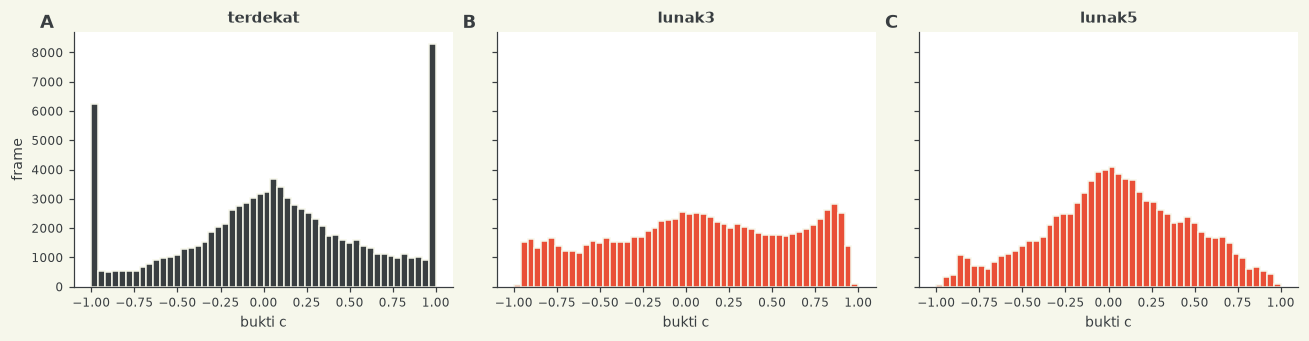

In [2]:
dist = common.team_distances()
dH, dA = dist[:, 0], dist[:, 1]
OBS_N = np.isfinite(dH) & np.isfinite(dA)
C_N = np.zeros(N); C_N[OBS_N] = np.clip(dA[OBS_N] - dH[OBS_N], -10, 10) / 10
C_S3, OBS_S3 = common.soft_control(3.0)
C_S5, OBS_S5 = common.soft_control(5.0)
EV = {"terdekat": (C_N, OBS_N), "lunak3": (C_S3, OBS_S3), "lunak5": (C_S5, OBS_S5)}

rows = []
for k, (c, o) in EV.items():
    g = GRADED & o
    rows.append({"bukti": k, "frame dinilai dengan bukti": f"{g.sum() / GRADED.sum():.1%}",
                 "|c| < 0,2": f"{np.mean(np.abs(c[g]) < 0.2):.1%}", "|c| > 0,6": f"{np.mean(np.abs(c[g]) > 0.6):.1%}"})
display(pd.DataFrame(rows))
both = GRADED & OBS_N & OBS_S3
print(f"tanda tim sama antara 'terdekat' dan 'lunak3': {np.mean(np.sign(C_N[both]) == np.sign(C_S3[both])):.1%}")

fig, ax = plt.subplots(1, 3, figsize=(12, 3.2), sharey=True)
for a, (k, (c, o)), col in zip(ax, EV.items(), (C2, C1, C1)):
    a.hist(c[GRADED & o], bins=50, range=(-1, 1), color=col, edgecolor=C3); a.set(title=k, xlabel="bukti c")
ax[0].set_ylabel("frame")
for a, l in zip(ax, "ABC"): panel(a, l)
fig.tight_layout(); plt.show()

Bukti lunak lebih terkonsentrasi di dekat ±1 pada frame yang membedakan tim, dan frame tanpa pemain dalam jangkauan dikeluarkan dari bukti (bukan dipaksa menjadi tebakan). Kesepakatan tanda dengan bukti terdekat menunjukkan seberapa besar kedua cara melihat hal yang sama.

## [2] EM tanpa label

EM memperkirakan $m$, $s$, dan $q$ dengan memaksimalkan kemungkinan data. Kestabilan diperiksa dengan melatih terpisah pada tiap babak dan membandingkan parameternya dengan hasil gabungan; bila parameter jauh berbeda antar babak, estimasinya tidak bisa dipercaya.

In [3]:
PARAMS, ROWS, HIST = {}, [], {}
for k, (c, o) in EV.items():
    fit = {"gabungan": common.hmm2_em(c, o, BL, n_iter=60, tol=1e-6),
           "babak 1": common.hmm2_em(c, o, [BL[0]], n_iter=60, tol=1e-6),
           "babak 2": common.hmm2_em(c, o, [BL[1]], n_iter=60, tol=1e-6)}
    PARAMS[k] = fit["gabungan"]; HIST[k] = fit["gabungan"]["ll_hist"]
    for scope, p in fit.items():
        ROWS.append({"bukti": k, "data": scope, "m": round(p["m"], 3), "s": round(p["s"], 3), "m/s": round(p["m"] / p["s"], 2),
                     "q": round(p["q"], 5), "λ = log((1-q)/q)": round(np.log((1 - p["q"]) / p["q"]), 2),
                     "durasi tim rata-rata (dtk)": round(1 / p["q"] / FPS, 1), "iterasi": len(p["ll_hist"])})
display(pd.DataFrame(ROWS))

,bukti,data,m,s,m/s,q,λ = log((1-q)/q),durasi tim rata-rata (dtk),iterasi
0,terdekat,gabungan,0.440,0.341,1.29,0.01278,4.35,3.1,9
1,terdekat,babak 1,0.449,0.346,1.30,0.01292,4.34,3.1,9
2,terdekat,babak 2,0.431,0.336,1.28,0.01265,4.36,3.2,9
3,lunak3,gabungan,0.454,0.291,1.56,0.01187,4.42,3.4,9
4,lunak3,babak 1,0.460,0.297,1.55,0.01142,4.46,3.5,9
5,lunak3,babak 2,0.448,0.286,1.57,0.01232,4.38,3.2,9
6,lunak5,gabungan,0.329,0.249,1.32,0.00874,4.73,4.6,10
7,lunak5,babak 1,0.333,0.251,1.33,0.00849,4.76,4.7,9
8,lunak5,babak 2,0.326,0.247,1.32,0.00898,4.70,4.5,10


Dua hal yang dibaca dari tabel: (a) apakah λ yang dipelajari jauh dari tebakan 50 nat dan ke arah mana, (b) apakah baris `babak 1` dan `babak 2` konsisten dengan `gabungan`. Catatan: $q$ adalah peluang ganti per frame, dan "durasi tim rata-rata" adalah $1/q$ frame. Ini bukan durasi possession final, karena possession juga dipecah oleh bola mati.

## [2b] EM dengan koreksi autokorelasi (likelihood bertenaga)

EM biasa memperlakukan tiap frame 25 fps sebagai bukti independen. Bukti sebenarnya sangat berautokorelasi, sehingga peluang ganti $q$ dipaksa membesar untuk menjelaskan derau yang sebenarnya satu kejadian panjang. Koreksinya: pangkatkan likelihood emisi dengan $\alpha = 1/\tau$, dengan $\tau$ waktu autokorelasi terintegrasi dari **residual** bukti (bukti dikurangi rata-rata keadaan hasil decode lengket). $\tau$ dihitung dari data, tanpa label. Pada data sintetis dengan derau berautokorelasi, EM biasa melebihkan $q$ sekitar 2,6 kali, dan versi ini sedikit menyepelekannya (0,55 kali); tebakan ini tidak sempurna tetapi searah koreksi yang benar.

In [4]:
TAU, ALPHA, TPARAMS, ROWS2 = {}, {}, {}, []
for k, (c, o) in EV.items():
    p0 = PARAMS[k]
    path0, _ = common.em_decode(c, o, BL, {**p0, "q": 1e-4})          # decode lengket sebagai acuan keadaan
    res = np.zeros(N)
    for (a, b), pth in zip(BL, path0):
        res[a:b + 1] = c[a:b + 1] - p0["m"] * np.where(pth == 0, 1.0, -1.0)
    TAU[k] = common.integrated_autocorr_time(res, o & GRADED)
    ALPHA[k] = 1.0 / TAU[k]
    TPARAMS[k] = common.hmm2_em(c, o, BL, n_iter=80, tol=1e-6, alpha=ALPHA[k])
    q = TPARAMS[k]["q"]
    ROWS2.append({"bukti": k, "tau (frame)": round(TAU[k], 1), "alpha": round(ALPHA[k], 4), "m": round(TPARAMS[k]["m"], 3),
                  "s": round(TPARAMS[k]["s"], 3), "q": round(q, 5), "λ = log((1-q)/q)": round(np.log((1 - q) / q), 2),
                  "durasi tim rata-rata (dtk)": round(1 / q / FPS, 1)})
display(pd.DataFrame(ROWS2))

,bukti,tau (frame),alpha,m,s,q,λ = log((1-q)/q),durasi tim rata-rata (dtk)
0,terdekat,80.9,0.0124,0.296,0.471,0.00086,7.06,46.4
1,lunak3,44.5,0.0225,0.343,0.417,0.00148,6.52,27.1
2,lunak5,90.4,0.0111,0.192,0.365,0.00084,7.09,47.9


Bandingkan kolom λ dengan tabel [2]: koreksi seharusnya menaikkan λ. Apakah naik cukup untuk menghasilkan possession yang berdurasi masuk akal, diperiksa pada [3] dan [4].

## [3] Decoder dan bola mati

Viterbi memakai parameter hasil EM gabungan. Bola mati: gap bola yang oleh pengklasifikasi 004 diprediksi restart (θ = 0,5) menjadi `D`; 2.934 frame pra-kick-off babak kedua `D`; frame di luar babak `X`.

In [5]:
G = common.gap_dead_ball()
DEAD = G[G.p_dead >= 0.5]
print(f"gap >= 2 dtk: {len(G)} | diprediksi mati: {len(DEAD)} | frame D dari gap: {DEAD.dur.sum() * FPS / GRADED.sum():.1%}")

def finish(team_paths):
    labels = np.full(N, "X", dtype="<U1")
    for (half, a, b), path in zip(BLOCKS3, team_paths):
        labels[a:b + 1] = np.where(path == 0, "H", "A")
        if half == 2: labels[a:KICKOFF2] = "D"
    for _, r in DEAD.iterrows():
        labels[int(r.f0):int(r.f1)] = "D"
    return labels

def possessions(labels):
    n, durs = 0, []
    for _, a, b in BLOCKS3:
        seg = labels[a:b + 1]
        for t in ("H", "A"):
            s, e = common.runs(seg == t); n += len(s); durs += list((e - s) / FPS)
    return n, float(np.mean(durs))

LAB, LAMS = {}, {}
for k, (c, o) in EV.items():
    paths, lam = common.em_decode(c, o, BL, PARAMS[k])
    LAB[k] = finish(paths); LAMS[k] = lam

for k, (c, o) in EV.items():
    paths, lam = common.em_decode(c, o, BL, TPARAMS[k], alpha=ALPHA[k])
    LAB[k + "_temp"] = finish(paths); LAMS[k + "_temp"] = lam

# acuan: konfigurasi 004 (terdekat, tau = 3 m, lambda = 50 ditetapkan tangan)
E = np.zeros(N); E[OBS_N] = np.clip((dA[OBS_N] - dH[OBS_N]) / 3.0, -10, 10)
lpH, lpA = -np.logaddexp(0, -E), -np.logaddexp(0, E); lpH[~OBS_N] = 0; lpA[~OBS_N] = 0
LAB["ref_004_lam50"] = finish([common.viterbi_2state(lpH[a:b + 1], lpA[a:b + 1], 50.0) for a, b in BL])
for k, lab in LAB.items():
    n, d = possessions(lab); print(f"{k:16s} possession {n:4d} | durasi rata-rata {d:5.1f} dtk | D {np.mean(lab[GRADED] == 'D'):.1%}")

gap >= 2 dtk: 131 | diprediksi mati: 37 | frame D dari gap: 20.8%


terdekat         possession 1056 | durasi rata-rata   4.7 dtk | D 22.7%
lunak3           possession 1063 | durasi rata-rata   4.6 dtk | D 22.7%
lunak5           possession  769 | durasi rata-rata   6.4 dtk | D 22.7%
terdekat_temp    possession   55 | durasi rata-rata  89.3 dtk | D 22.7%
lunak3_temp      possession   95 | durasi rata-rata  51.7 dtk | D 22.7%
lunak5_temp      possession   47 | durasi rata-rata 104.5 dtk | D 22.7%
ref_004_lam50    possession  191 | durasi rata-rata  25.7 dtk | D 22.7%


## [4] Varian yang dibangun

Tiga varian dengan EM biasa (jenis bukti berbeda), tiga dengan EM terkoreksi autokorelasi, satu acuan 004 dengan konstanta tangan, dan baseline `smooth50`.

,varian,λ,possession,durasi rata2 (dtk),% D (dinilai)
0,v1_nearest_em,4.3,1056,4.7,22.7
1,v2_soft3_em,4.4,1063,4.6,22.7
2,v3_soft5_em,4.7,769,6.4,22.7
3,v4_nearest_em_temp,7.1,55,89.3,22.7
4,v5_soft3_em_temp,6.5,95,51.7,22.7
5,v6_soft5_em_temp,7.1,47,104.5,22.7
6,ref_004_lam50,50.0,191,25.7,22.7
7,baseline_smooth50,NaN,594,7.2,32.3


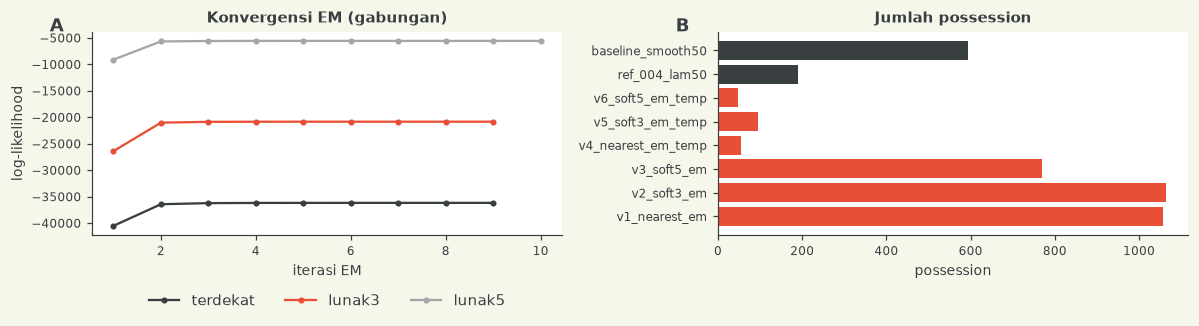

In [6]:
NAMES = {"terdekat": "v1_nearest_em", "lunak3": "v2_soft3_em", "lunak5": "v3_soft5_em", "terdekat_temp": "v4_nearest_em_temp",
         "lunak3_temp": "v5_soft3_em_temp", "lunak5_temp": "v6_soft5_em_temp", "ref_004_lam50": "ref_004_lam50"}
for old in OUT.glob("*.csv"): old.unlink()
rows = []
for k, name in NAMES.items():
    write_submission(str(OUT / f"{name}.csv"), LAB[k])
    n, d = possessions(LAB[k])
    rows.append({"varian": name, "λ": round(LAMS.get(k, 50.0), 1), "possession": n, "durasi rata2 (dtk)": round(d, 1),
                 "% D (dinilai)": round(100 * np.mean(LAB[k][GRADED] == "D"), 1)})
codes = common.cached("atd_nearest", lambda: None)
base = np.full(N, "X", dtype="<U1"); sm = smooth(codes, 50)
for _, a, b in BLOCKS3: base[a:b + 1] = sm[a:b + 1]
write_submission(str(OUT / "baseline_smooth50.csv"), base)
n, d = possessions(base)
rows.append({"varian": "baseline_smooth50", "λ": None, "possession": n, "durasi rata2 (dtk)": round(d, 1), "% D (dinilai)": round(100 * np.mean(base[GRADED] == "D"), 1)})
display(pd.DataFrame(rows))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
for k, col in zip(HIST, (C2, C1, GREY)):
    ax[0].plot(range(1, len(HIST[k]) + 1), HIST[k], marker="o", ms=3, color=col, label=k)
ax[0].set(xlabel="iterasi EM", ylabel="log-likelihood", title="Konvergensi EM (gabungan)")
ax[0].legend(loc="upper center", bbox_to_anchor=(0.5, -0.22), ncol=3)
names = [r["varian"] for r in rows]; pos = [r["possession"] for r in rows]
ax[1].barh(names, pos, color=[C1 if n.startswith("v") else C2 for n in names]); ax[1].set(xlabel="possession", title="Jumlah possession")
panel(ax[0], "A"); panel(ax[1], "B"); fig.tight_layout(); plt.show()

## [5] Validasi dan skor (pemeriksaan pipeline)

Skor GT publik hanya memeriksa bahwa berkas benar. Dengan 17 possession, selisih kecil adalah noise dan tidak dipakai untuk memilih varian.

In [7]:
for f in sorted(OUT.glob("*.csv")):
    r = subprocess.run([sys.executable, str(ROOT / "evaluation" / "validate_submission.py"), str(f)], capture_output=True, text=True)
    print(f.name, "->", "VALID" if "Valid." in r.stdout else r.stdout[-200:])
subprocess.run([sys.executable, str(ROOT / "evaluation" / "run_evaluation.py"), "--results", str(OUT), "--out", str(OUT / "reports")], capture_output=True, text=True)
board = pd.read_csv(OUT / "reports" / "scoreboard.csv")
display(board[["rank", "submission", "macro_f1", "spell_f1_mean", "poss", "dur"]].round(4))

baseline_smooth50.csv -> VALID


ref_004_lam50.csv -> VALID


v1_nearest_em.csv -> VALID


v2_soft3_em.csv -> VALID


v3_soft5_em.csv -> VALID


v4_nearest_em_temp.csv -> VALID


v5_soft3_em_temp.csv -> VALID


v6_soft5_em_temp.csv -> VALID


,rank,submission,macro_f1,spell_f1_mean,poss,dur
0,1,ref_004_lam50,0.6618,0.4000,9,31.7067
1,2,baseline_smooth50,0.6207,0.3256,26,10.8031
2,3,v5_soft3_em_temp,0.6597,0.3167,7,40.7657
3,4,v1_nearest_em,0.6049,0.0944,72,3.9633
4,5,v3_soft5_em,0.5801,0.0812,52,5.4877
5,6,v2_soft3_em,0.5890,0.0771,66,4.3236
6,7,v4_nearest_em_temp,0.3504,0.0211,2,142.6800
7,8,v6_soft5_em_temp,0.3504,0.0211,2,142.6800


# Ringkasan 005

**Yang dikerjakan.** Dua perubahan dari 004 dibuat terpisah: (1) bukti tim lunak (kendali atas seluruh pemain, σ = 3 m atau 5 m) selain bukti pemain terdekat, dan (2) λ dipelajari dari data pertandingan sendiri lewat EM pada HMM dua keadaan tanpa label, baik EM biasa maupun EM dengan likelihood bertenaga 1/τ untuk mengoreksi autokorelasi bukti. Bola mati tetap dari pengklasifikasi gap 004 (D 22,7% frame dinilai). Semua delapan berkas lolos `validate_submission.py`. Tidak ada label tangan, tidak ada GT untuk pelatihan, tidak ada data keluar dari mesin; komputasi sepenuhnya lokal (EM selesai dalam detik), jadi molab tidak dipakai.

**Hasil.**
1. **Bukti lunak sedikit lebih tajam.** Frame ambigu (|c| < 0,2) turun dari 32,5% (terdekat) menjadi 25,8% (σ = 3 m); tanda timnya sama dengan bukti terdekat pada 92,6% frame.
2. **EM biasa stabil tetapi salah sasaran.** λ yang dipelajari hampir identik antar babak (4,3 sampai 4,4 untuk bukti terdekat dan lunak σ = 3 m), tetapi hanya sekitar 4,4 nat, sehingga muncul sekitar 1.060 possession berdurasi rata-rata 4,7 detik. spellF1 GT publik jatuh menjadi 0,09. Penyebabnya: EM menganggap tiap frame 25 fps independen, padahal bukti berautokorelasi kuat, sehingga peluang ganti membesar untuk menyerap derau. Kegagalan yang sama terlihat pada data sintetis (q melebihi 2,6 kali).
3. **EM terkoreksi autokorelasi bergeser terlalu jauh.** Dengan α = 1/τ (τ sekitar 45 sampai 90 frame, dihitung dari residual bukti), λ naik ke 6,5 sampai 7,1 nat dan possession turun menjadi 47 sampai 95 dengan durasi rata-rata 52 sampai 104 detik, jauh terlalu panjang. Pada jendela GT publik, dua varian (terdekat dan σ = 5 m) hanya memprediksi 2 possession (spellF1 0,02); varian lunak σ = 3 m mendapat 0,317.
4. **Konstanta tangan 004 (λ = 50) berada di antara dua ekstrem** (191 possession, 25,7 detik), tetapi itu kebetulan yang tidak terverifikasi, bukan hasil prinsip.

**Kesimpulan.** Laju pergantian possession **tidak teridentifikasi** dari bukti per frame saja: dua perlakuan yang sama-sama beralasan memberi hasil yang berbeda 20 sampai 200 kali pada jumlah possession. Selisih skor GT publik antar varian ada dalam noise 17 possession, jadi tidak ada klaim perbaikan atas 004 maupun baseline.

**Langkah berikutnya.** Perlu prior dari luar pertandingan ini. Yang diizinkan `RULES.md` adalah data **pertandingan lain** yang bisa diakses panitia dan dijelaskan dalam dokumen teknis (mis. statistik durasi possession dari data terbuka pertandingan lain). Lalu λ dipilih agar distribusi durasi possession prediksi cocok dengan distribusi acuan itu, tanpa menyentuh GT pertandingan ini. Alternatif: bukti video lokal untuk pergantian possession.